# EDA kho văn bản luật giao thông đường bộ

Phần A của mục 6 bản thiết kế dự án. Dữ liệu: `data/processed/legal_units_versioned.jsonl` (bản chốt `data-v1`, sau PR #6 kiểm tra dữ liệu cuối).
Thời điểm phân tích T = 01/10/2026; "có hiệu lực" tính bằng `lawproc.validity.in_force_at` (có xét ngoại lệ).
Mỗi phân tích kết thúc bằng **Phát hiện → hành động**. Số liệu máy đọc lưu ở `reports/eda/summary.json`.
Bản ghi có điều kiện cần được đối chiếu với điều kiện áp dụng trước khi trả lời câu hỏi pháp lý.

**Chạy lại từ thư mục gốc:** môi trường Python 3.13 cần các thư viện đã ghim trong `requirements.txt`
và hai `tokenizer.json` tại đường dẫn `config.TOKENIZERS` (không cần trọng số mô hình).
Đăng ký kernel cho Python của dự án rồi tạo/chạy notebook bằng các lệnh sau
(Linux/macOS: thay `py -3.13` bằng Python của môi trường):

```powershell
py -3.13 -m ipykernel install --user --name python313-traffic-law --display-name "Python 3.13 (traffic-law)"
py -3.13 scripts/build_notebook.py notebooks/01_eda_kho_luat.py
py -3.13 -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=python313-traffic-law --ExecutePreprocessor.timeout=3600 notebooks/01_eda_kho_luat.ipynb
```
Môi trường hiện tại đã có thư viện/kernel/tokenizer; không tải thêm để thực hiện notebook.

**Đơn vị thống kê:** các thống kê theo đơn vị có hiệu lực tại T dùng bản đại diện mới nhất của mỗi `unit_id`.
Đây là thống kê mô tả, không chứng minh nội dung mới nhất áp dụng chung cho mọi đối tượng.
E5 phân tích các dòng CSV sửa đổi đã duyệt và toàn bộ phiên bản lưu để thống kê lịch sử sửa đổi.
E6 dựng dòng thời gian và đếm lượt sự kiện tương lai từ toàn bộ bản ghi lưu, kể cả phiên bản không có hiệu lực tại T.
Kiểm tra khoảng trống nguồn E10 cũng xét toàn bộ phiên bản lưu, độc lập với T.
`live_all` giữ mọi phiên bản có hiệu lực; sáu bản thuộc ba `unit_id` nhiều nhánh được hiển thị riêng bên dưới
và đo token riêng ở E3. Ghép Khoản–Điểm dưới đây chỉ tạo ứng viên đo độ dài, chưa tạo đoạn pháp lý dùng cho RAG;
khi triển khai phải ghép các phiên bản tương thích và giữ đầy đủ điều kiện áp dụng.

In [1]:
import csv
import json
import re
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import math

import matplotlib.pyplot as plt
import pandas as pd

from lawproc import config, eda
from lawproc.structure import is_closing_line
from lawproc.validity import in_force_at

T = config.CUTOFF
FIG = ROOT / "reports" / "eda" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 80)


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def read_csv(path):
    return list(csv.DictReader(path.open(encoding="utf-8-sig")))

In [2]:
recs = [json.loads(x) for x in (config.PROCESSED / "legal_units_versioned.jsonl").open(encoding="utf-8")]
nhom = {r["doc_id"]: r["nhom"] for r in read_csv(config.MANIFEST)}
nhom.update({k: v["nhom"] for k, v in config.DERIVED_DOCS.items()})
method = {r["doc_id"]: r["method"] for r in read_csv(config.PROCESSED / "assembly_report.csv")}
for r in recs:
    r["in_force"], r["dieu_kien_hl"] = in_force_at(r, T)
    r["nhom"] = nhom[r["doc_id"]]
    r["van_ban_sua_doi"] = r["doc_id"] in config.AMENDING_DOCS
df = pd.DataFrame(recs)
live_all = df[df["in_force"]].reset_index(drop=True)
variants = live_all[live_all.duplicated("unit_id", keep=False)].copy()
# Đại diện mới nhất cho số liệu theo đơn vị. Các nhánh cũ có điều kiện vẫn được giữ trong live_all/variants.
live = (live_all.sort_values(["unit_id", "valid_from", "version_id"])
        .drop_duplicates("unit_id", keep="last").reset_index(drop=True))
print(f"{len(df)} bản ghi, {df['doc_id'].nunique()} văn bản; {len(live_all)} phiên bản có hiệu lực tại {T}, "
      f"{len(live)} unit_id phân biệt; {len(variants)} phiên bản thuộc {variants['unit_id'].nunique()} "
      f"unit_id có nhiều nhánh; {int(live_all['dieu_kien_hl'].notna().sum())} phiên bản kèm điều kiện")
with pd.option_context("display.max_colwidth", None):
    display(variants[["unit_id", "version_id", "valid_from", "valid_to", "dieu_kien_hl"]])

20500 bản ghi, 40 văn bản; 17674 phiên bản có hiệu lực tại 2026-10-01, 17671 unit_id phân biệt; 6 phiên bản thuộc 3 unit_id có nhiều nhánh; 16 phiên bản kèm điều kiện


,unit_id,version_id,valid_from,valid_to,dieu_kien_hl
3776,luat_36_2024:d35:k2,luat_36_2024:d35:k2@2025-01-01,2025-01-01,2026-07-01,"Đến hết 31/12/2027, yêu cầu lắp thiết bị ghi nhận hình ảnh người lái xe chưa áp dụng với xe ô tô kinh doanh vận tải hành khách dưới 08 chỗ, xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo), xe vận tải nội bộ; các xe còn lại áp dụng như bản trước; Yêu cầu lắp thiết bị ghi nhận hình ảnh khoang chở khách đối với xe ô tô kinh doanh vận tải hành khách từ 08 chỗ trở lên áp dụng từ 01/01/2029 theo lộ trình của Chính phủ"
6507,nd_168_2024:d20:k5:l,nd_168_2024:d20:k5:l@2025-01-01,2025-01-01,2026-08-15,"Đến hết 31/12/2027, quy định về thiết bị ghi nhận hình ảnh người lái xe chỉ áp dụng với xe ô tô chở người từ 08 chỗ trở lên kinh doanh vận tải hành khách (như bản trước); với xe kinh doanh vận tải hành khách dưới 08 chỗ và xe vận tải nội bộ áp dụng từ 01/01/2028"
6529,nd_168_2024:d21:k3:b,nd_168_2024:d21:k3:b@2025-01-01,2025-01-01,2026-08-15,"Đến hết 31/12/2027, chỉ áp dụng với xe ô tô đầu kéo (như bản trước); với xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo) và xe vận tải nội bộ áp dụng từ 01/01/2028"
17050,luat_36_2024:d35:k2,luat_36_2024:d35:k2@2026-07-01,2026-07-01,NaN,"Đến hết 31/12/2027, yêu cầu lắp thiết bị ghi nhận hình ảnh người lái xe chưa áp dụng với xe ô tô kinh doanh vận tải hành khách dưới 08 chỗ, xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo), xe vận tải nội bộ; các xe còn lại áp dụng như bản trước; Yêu cầu lắp thiết bị ghi nhận hình ảnh khoang chở khách đối với xe ô tô kinh doanh vận tải hành khách từ 08 chỗ trở lên áp dụng từ 01/01/2029 theo lộ trình của Chính phủ"
17611,nd_168_2024:d20:k5:l,nd_168_2024:d20:k5:l@2026-08-15,2026-08-15,NaN,"Đến hết 31/12/2027, quy định về thiết bị ghi nhận hình ảnh người lái xe chỉ áp dụng với xe ô tô chở người từ 08 chỗ trở lên kinh doanh vận tải hành khách (như bản trước); với xe kinh doanh vận tải hành khách dưới 08 chỗ và xe vận tải nội bộ áp dụng từ 01/01/2028"
17616,nd_168_2024:d21:k3:b,nd_168_2024:d21:k3:b@2026-08-15,2026-08-15,NaN,"Đến hết 31/12/2027, chỉ áp dụng với xe ô tô đầu kéo (như bản trước); với xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo) và xe vận tải nội bộ áp dụng từ 01/01/2028"


## E1. Quy mô kho

In [3]:
e1_doc = (live.groupby(["nhom", "doc_id"])["level"].value_counts().unstack(fill_value=0)
          .reindex(columns=["dieu", "khoan", "diem", "phu_luc"], fill_value=0))
e1_doc["tong"] = e1_doc.sum(axis=1)
e1_doc.sort_values("tong", ascending=False)

level                                     dieu  khoan  diem  phu_luc  tong
nhom             doc_id                                                   
Tai nạn          vbhn_135_2025_blhs        409   1324  2833        0  4566
                 blds_2015                 689   1418   312        0  2419
Xử phạt          nd_168_2024                55    337   912        0  1304
Luật lõi         luat_36_2024               89    443   443        0   975
Hướng dẫn        nd_158_2024                76    351   501       12   940
                 nd_165_2024                71    305   483        8   867
Luật lõi         luat_35_2024               85    384   382        0   851
Nộp phạt, giữ xe vbhn_90_2026_xlvphc       126    398   261        0   785
Bảo hiểm         nd_67_2023                 78    251   253        9   591
GPLX             tt_108_2026_bca            43    170   249       14   476
Xử phạt          nd_336_2025                28    120   294        0   442
Đăng ký xe       tt_79_2024_bca             40    173   188       10   411
Biển báo         qcvn_41_2024               84    270    36        9   399
Đăng kiểm        tt_30_2026_bxd             32    136   173       20   361
GPLX             nd_94_2026                 43    129   159       19   350
Hướng dẫn        nd_218_2026                39    112   168        7   326
                 nd_241_2026                28     99   138        7   272
Luật lõi         luat_118_2025              11    123    80        0   214
Xử phạt          nd_238_2026                21     60    73        0   154
Đăng ký xe       tt_13_2025_bca             14     88    32       17   151
Nộp phạt, giữ xe nd_138_2021                21     80    49        0   150
Đăng ký xe       nd_156_2024                29     70    38        6   143
Lệ phí           nd_10_2022                 14     68    41        0   123
GPLX             tt_65_2024_bca             11     33    22        0    66
Tốc độ           tt_38_2024_bgtvt           12     32    11        0    55
GPLX             tt_36_2024_byt             10     26    14        2    52
Đăng ký xe       tt_62_2026_bca             10     28     7        1    46
Lệ phí           tt_155_2025_btc             8     23     7        1    39
Bảo hiểm         nd_220_2026                10     13     0        2    25
Lệ phí           nd_175_2025                 2     11    10        0    23
GPLX             tt_105_2026_bca             7     10     2        1    20
Đăng ký xe       tt_51_2025_bca              3     10     5        1    19
Nộp phạt, giữ xe nd_47_2026                  6     11     0        0    17
GPLX             tt_12_2025_bca              0      3     9        5    17
Đăng ký xe       tt_37_2026_bca              8      5     0        1    14
Biển báo         tt_51_2024_bgtvt_qcvn41     2      2     0        0     4
Lệ phí           nd_51_2025                  2      2     0        0     4

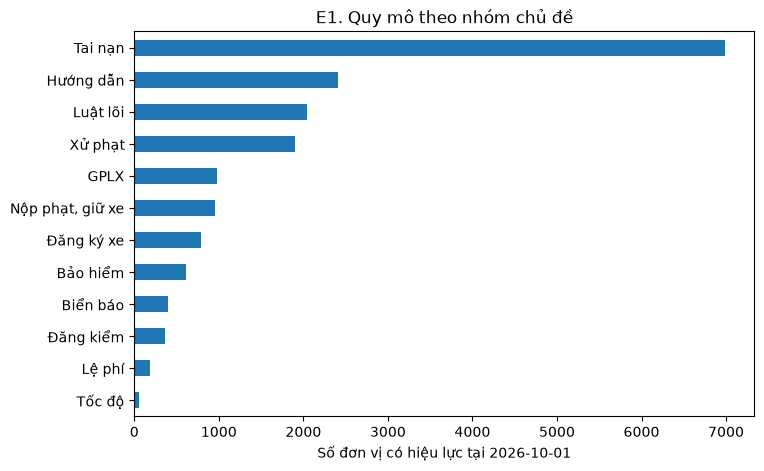

,van_ban,don_vi
nhom,,
Tốc độ,1,55
Lệ phí,4,189
Đăng kiểm,1,361
Biển báo,2,403
Bảo hiểm,2,616
Đăng ký xe,6,784
"Nộp phạt, giữ xe",3,952
GPLX,6,981
Xử phạt,3,1900


In [4]:
e1_nhom = live.groupby("nhom").agg(van_ban=("doc_id", "nunique"), don_vi=("unit_id", "size")).sort_values("don_vi")
fig, ax = plt.subplots(figsize=(8, 5))
e1_nhom["don_vi"].plot.barh(ax=ax)
ax.set_xlabel(f"Số đơn vị có hiệu lực tại {T}")
ax.set_ylabel("")
ax.set_title("E1. Quy mô theo nhóm chủ đề")
save(fig, "e1_quy_mo_nhom.png")
e1_nhom

In [5]:
sd = live[live["van_ban_sua_doi"]]
print(f"Văn bản sửa đổi: {sd['doc_id'].nunique()} văn bản, {len(sd)} đơn vị của chính văn bản đó "
      f"(phần lớn là câu chỉ dẫn 'sửa đổi, bổ sung…'; nội dung mới đã được áp vào văn bản gốc)")

Văn bản sửa đổi: 13 văn bản, 1285 đơn vị của chính văn bản đó (phần lớn là câu chỉ dẫn 'sửa đổi, bổ sung…'; nội dung mới đã được áp vào văn bản gốc)


**Phát hiện → hành động (E1):**

- **Phát hiện:** 20.500 phiên bản của 40 văn bản; tại T có 17.674 phiên bản có hiệu lực nhưng chỉ 17.671 `unit_id`, gồm 2.216 Điều, 7.118 Khoản, 8.185 Điểm và 152 phụ lục → **Hành động:** ở bước lập chỉ mục, tách địa chỉ đơn vị khỏi phiên bản và lưu ngày hiệu lực cùng nguồn trích dẫn.
- **Phát hiện:** 6 phiên bản thuộc 3 địa chỉ nhiều nhánh, tổng cộng 16 phiên bản có ghi chú điều kiện → **Hành động:** ở bước lọc truy hồi, đối chiếu điều kiện và đối tượng; không dùng quy tắc chọn bản mới nhất làm kết luận pháp lý chung.
- **Phát hiện:** nhóm Tai nạn có 6.985 đơn vị, còn Tốc độ có 55; 13 văn bản sửa đổi chứa 1.285 đơn vị → **Hành động:** ở bước tạo kho RAG, dùng phạm vi E2 đã chốt và tách chỉ dẫn sửa đổi khỏi nội dung đích đã áp sửa đổi; bộ eval lấy phân bổ theo căn bậc hai thay vì tỷ lệ thô.

## E2. Phạm vi thực của BLDS 2015 và BLHS (VBHN 135)

Phạm vi đã chốt (2026-10-16, `config.SCOPE_DIEU`): BLDS Chương XX (Điều 584–608, bồi thường thiệt hại ngoài hợp đồng,
có Điều 601 nguồn nguy hiểm cao độ); BLHS Điều 260–266 (các tội về giao thông đường bộ). Dữ liệu đã mang cờ
`trong_pham_vi` theo phạm vi này; notebook tính lại để kiểm tra cờ. Chương XX BLDS rộng hơn riêng giao thông đường bộ.

BLDS + BLHS: 6985 / 17671 đơn vị có hiệu lực (39.5%); trong phạm vi đã chốt: 213


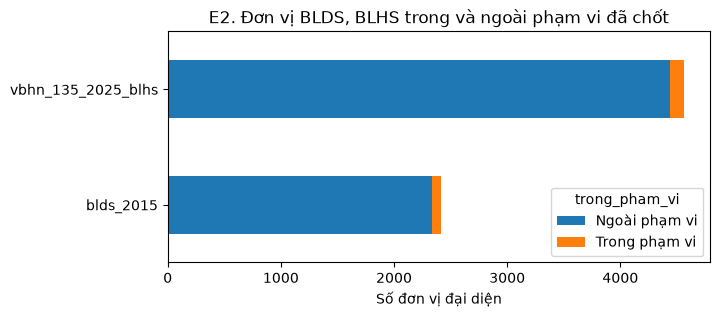

trong_pham_vi,False,True
doc_id,,
blds_2015,2334,85
vbhn_135_2025_blhs,4438,128


In [6]:
SCOPE = config.SCOPE_DIEU


def in_scope(doc_id, dieu):
    rng = SCOPE.get(doc_id)
    if not rng:
        return True
    m = re.match(r"\d+", dieu or "")
    return bool(m) and rng[0] <= int(m.group()) <= rng[1]


assert live["trong_pham_vi"].tolist() == [in_scope(d, x) for d, x in zip(live["doc_id"], live["dieu"])]
big = live[live["doc_id"].isin(SCOPE)]
print(f"BLDS + BLHS: {len(big)} / {len(live)} đơn vị có hiệu lực ({len(big) / len(live):.1%}); "
      f"trong phạm vi đã chốt: {int(big['trong_pham_vi'].sum())}")
e2 = big.groupby(["doc_id", "trong_pham_vi"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3))
e2.rename(columns={False: "Ngoài phạm vi", True: "Trong phạm vi"}).plot.barh(stacked=True, ax=ax)
ax.set_xlabel("Số đơn vị đại diện")
ax.set_ylabel("")
ax.set_title("E2. Đơn vị BLDS, BLHS trong và ngoài phạm vi đã chốt")
save(fig, "e2_pham_vi_blds_blhs.png")
e2

In [7]:
check = big[(big["level"] == "dieu")]
check = check[[(SCOPE[d][0] - 5) <= int(re.match(r"\d+", x).group()) <= (SCOPE[d][1] + 5)
               for d, x in zip(check["doc_id"], check["dieu"])]]
check[["doc_id", "dieu", "title", "trong_pham_vi"]]

,doc_id,dieu,title,trong_pham_vi
1810,blds_2015,579,Nghĩa vụ hoàn trả,False
1820,blds_2015,580,Tài sản hoàn trả,False
1825,blds_2015,581,"Nghĩa vụ hoàn trả hoa lợi, lợi tức",False
1828,blds_2015,582,Quyền yêu cầu người thứ ba hoàn trả,False
1829,blds_2015,583,Nghĩa vụ thanh toán,False
1830,blds_2015,584,Căn cứ phát sinh trách nhiệm bồi thường thiệt hại,True
1834,blds_2015,585,Nguyên tắc bồi thường thiệt hại,True
1840,blds_2015,586,Năng lực chịu trách nhiệm bồi thường thiệt hại của cá nhân,True
1844,blds_2015,587,Bồi thường thiệt hại do nhiều người cùng gây ra,True
1845,blds_2015,588,Thời hiệu khởi kiện yêu cầu bồi thường thiệt hại,True


**Phát hiện → hành động (E2):**

- **Phát hiện:** BLDS và BLHS chiếm 6.985/17.671 đơn vị đại diện (39,5%), nhưng khoảng đã chốt chỉ giữ 213 đơn vị và để ngoài phạm vi 6.772 đơn vị → **Hành động:** ở bước xây kho thử nghiệm, dùng cờ `trong_pham_vi` có sẵn trong dữ liệu thay vì xóa dữ liệu; kho tra cứu, bộ eval và dữ liệu train chỉ lấy 213 đơn vị trong phạm vi.
- **Phát hiện:** bảng tiêu đề có 25 Điều BLDS 584–608 và 7 Điều BLHS 260–266; Điều 267 BLHS chuyển sang đường sắt → **Hành động:** giữ hai khoảng đã chốt (`config.SCOPE_DIEU`); dùng BLDS như nguồn hỗ trợ bồi thường dân sự, không gán toàn bộ Chương XX là luật giao thông.

## E3. Độ dài đơn vị (từ, token Qwen3.5-9B, token bge-m3)

`so_tu` dùng regex `\w+`: đếm các đơn vị chữ/số, gần với âm tiết viết cách ở tiếng Việt,
không phải số từ đã tách bằng Pyvi. Pyvi chỉ dùng cho phân tích từ vựng E7.

In [8]:
tokenizer_provenance = [
    {"key": "qwen", "name": "Qwen3.5-9B",
     "url": "https://huggingface.co/Qwen/Qwen3.5-9B/resolve/main/tokenizer.json",
     "bytes": 12807982, "sha256": "5f9e4d4901a92b997e463c1f46055088b6cca5ca61a6522d1b9f64c4bb81cb42"},
    {"key": "bge_m3", "name": "bge-m3",
     "url": "https://huggingface.co/BAAI/bge-m3/resolve/main/tokenizer.json",
     "bytes": 17098108, "sha256": "21106b6d7dab2952c1d496fb21d5dc9db75c28ed361a05f5020bbba27810dd08"},
]
for info in tokenizer_provenance:
    p = config.TOKENIZERS[info["key"]]
    assert p.stat().st_size == info["bytes"] and hashlib.sha256(p.read_bytes()).hexdigest() == info["sha256"]
    print(info["name"], info["url"], info["bytes"], info["sha256"])
texts = live["text"].tolist()
live["so_tu"] = [eda.count_words(t) for t in texts]
live["tok_qwen"] = eda.count_tokens(texts, config.TOKENIZERS["qwen"])
live["tok_bge"] = eda.count_tokens(texts, config.TOKENIZERS["bge_m3"])
lv = live[live["level"].isin(["dieu", "khoan", "diem", "phu_luc"])]
cols = ["so_tu", "tok_qwen", "tok_bge"]
e3 = lv.groupby("level")[cols].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)
display(e3)
variant_lengths = variants[["unit_id", "version_id", "valid_from", "dieu_kien_hl"]].copy()
variant_lengths["tok_qwen_body"] = eda.count_tokens(variants["text"].tolist(), config.TOKENIZERS["qwen"])
variant_lengths["tok_bge_body"] = eda.count_tokens(variants["text"].tolist(), config.TOKENIZERS["bge_m3"])
with pd.option_context("display.max_colwidth", None):
    display(variant_lengths)
print("Bảng theo level đo riêng text nguồn: chưa có title, địa chỉ, điều kiện, metadata hay prompt.")

Qwen3.5-9B https://huggingface.co/Qwen/Qwen3.5-9B/resolve/main/tokenizer.json 12807982 5f9e4d4901a92b997e463c1f46055088b6cca5ca61a6522d1b9f64c4bb81cb42
bge-m3 https://huggingface.co/BAAI/bge-m3/resolve/main/tokenizer.json 17098108 21106b6d7dab2952c1d496fb21d5dc9db75c28ed361a05f5020bbba27810dd08


so_tu                                                        \
          count    mean     std   min    50%     90%     95%      99%   
level                                                                   
diem     8185.0    37.0    39.0   2.0   25.0    77.0   109.0    189.0   
dieu     2216.0    14.0    51.0   0.0    0.0    47.0    71.0    137.0   
khoan    7118.0    48.0    52.0   2.0   34.0    91.0   126.0    245.0   
phu_luc   152.0  1764.0  2465.0  64.0  798.0  4550.0  5936.0  11137.0   

                 tok_qwen  ...          tok_bge                                \
             max    count  ...      max   count    mean     std   min     50%   
level                      ...                                                  
diem       524.0   8185.0  ...    645.0  8185.0    41.0    44.0   2.0    29.0   
dieu      1275.0   2216.0  ...   1431.0  2216.0    16.0    58.0   0.0     0.0   
khoan      993.0   7118.0  ...   1407.0  7118.0    53.0    64.0   3.0    38.0   
phu_luc  17684.0    152.0  ...  30088.0   152.0  2510.0  3307.0  86.0  1264.0   

                                           
            90%     95%      99%      max  
level                                      
diem       88.0   122.0    214.0    613.0  
dieu       51.0    78.0    155.0   1407.0  
khoan     102.0   139.0    277.0   1515.0  
phu_luc  6118.0  8511.0  14165.0  23935.0  

[4 rows x 27 columns]

,unit_id,version_id,valid_from,dieu_kien_hl,tok_qwen_body,tok_bge_body
3776,luat_36_2024:d35:k2,luat_36_2024:d35:k2@2025-01-01,2025-01-01,"Đến hết 31/12/2027, yêu cầu lắp thiết bị ghi nhận hình ảnh người lái xe chưa áp dụng với xe ô tô kinh doanh vận tải hành khách dưới 08 chỗ, xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo), xe vận tải nội bộ; các xe còn lại áp dụng như bản trước; Yêu cầu lắp thiết bị ghi nhận hình ảnh khoang chở khách đối với xe ô tô kinh doanh vận tải hành khách từ 08 chỗ trở lên áp dụng từ 01/01/2029 theo lộ trình của Chính phủ",70,68
6507,nd_168_2024:d20:k5:l,nd_168_2024:d20:k5:l@2025-01-01,2025-01-01,"Đến hết 31/12/2027, quy định về thiết bị ghi nhận hình ảnh người lái xe chỉ áp dụng với xe ô tô chở người từ 08 chỗ trở lên kinh doanh vận tải hành khách (như bản trước); với xe kinh doanh vận tải hành khách dưới 08 chỗ và xe vận tải nội bộ áp dụng từ 01/01/2028",90,89
6529,nd_168_2024:d21:k3:b,nd_168_2024:d21:k3:b@2025-01-01,2025-01-01,"Đến hết 31/12/2027, chỉ áp dụng với xe ô tô đầu kéo (như bản trước); với xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo) và xe vận tải nội bộ áp dụng từ 01/01/2028",68,69
17050,luat_36_2024:d35:k2,luat_36_2024:d35:k2@2026-07-01,2026-07-01,"Đến hết 31/12/2027, yêu cầu lắp thiết bị ghi nhận hình ảnh người lái xe chưa áp dụng với xe ô tô kinh doanh vận tải hành khách dưới 08 chỗ, xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo), xe vận tải nội bộ; các xe còn lại áp dụng như bản trước; Yêu cầu lắp thiết bị ghi nhận hình ảnh khoang chở khách đối với xe ô tô kinh doanh vận tải hành khách từ 08 chỗ trở lên áp dụng từ 01/01/2029 theo lộ trình của Chính phủ",176,172
17611,nd_168_2024:d20:k5:l,nd_168_2024:d20:k5:l@2026-08-15,2026-08-15,"Đến hết 31/12/2027, quy định về thiết bị ghi nhận hình ảnh người lái xe chỉ áp dụng với xe ô tô chở người từ 08 chỗ trở lên kinh doanh vận tải hành khách (như bản trước); với xe kinh doanh vận tải hành khách dưới 08 chỗ và xe vận tải nội bộ áp dụng từ 01/01/2028",76,77
17616,nd_168_2024:d21:k3:b,nd_168_2024:d21:k3:b@2026-08-15,2026-08-15,"Đến hết 31/12/2027, chỉ áp dụng với xe ô tô đầu kéo (như bản trước); với xe ô tô kinh doanh vận tải hàng hóa (trừ xe đầu kéo) và xe vận tải nội bộ áp dụng từ 01/01/2028",82,83


Bảng theo level đo riêng text nguồn: chưa có title, địa chỉ, điều kiện, metadata hay prompt.


Khoản + Điểm chỉ text nguồn (chưa có tiêu đề Điều): {'count': 7118.0, 'mean': 101.0, 'std': 119.0, 'min': 3.0, '50%': 62.0, '90%': 224.0, '95%': 321.0, '99%': 594.0, 'max': 2127.0} >512: 108
Chênh token sau khi ghép tiêu đề Điều (không phải phép cộng token độc lập): {'count': 7118.0, 'mean': 15.0, 'std': 14.0, 'min': 0.0, '50%': 11.0, '95%': 37.0, 'max': 148.0}
count    7118.0
mean      116.0
std       122.0
min         8.0
50%        77.0
90%       244.0
95%       344.0
99%       622.0
max      2168.0
dtype: float64
khoản + điểm > 256 token bge-m3: 652
khoản + điểm > 512 token bge-m3: 123
khoản + điểm > 1024 token bge-m3: 7
khoản + điểm > 8192 token bge-m3: 0


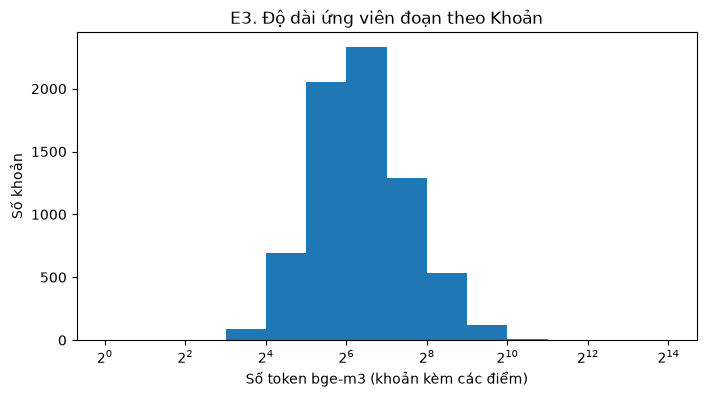

Khoản kèm Điểm và tiêu đề Điều, trong phạm vi RAG đã chốt: {'count': 3880.0, 'mean': 133.0, 'std': 136.0, 'min': 8.0, '50%': 88.0, '90%': 284.0, '95%': 389.0, '99%': 648.0, 'max': 2168.0} >512: 93


In [9]:
# Ứng viên cắt đoạn theo Khoản: tiêu đề Điều + nội dung Khoản + mọi Điểm trực thuộc.
# Các nhánh có điều kiện được đo riêng khi triển khai chunk; bản đại diện ở đây không thay thế điều kiện pháp lý.
diem = live[live["level"] == "diem"].copy()
diem["khoan_id"] = diem["unit_id"].str.rsplit(":", n=1).str[0]
extra = diem.groupby("khoan_id")["text"].agg("\n".join)
kh = live[live["level"] == "khoan"].set_index("unit_id")
dieu_heading = (live[live["level"] == "dieu"].set_index("unit_id")["title"])
kh_heading = dieu_heading.reindex(kh.index.str.rsplit(":", n=1).str[0]).fillna("")
kh_text = (kh_heading.to_numpy() + "\n" + kh["text"] + "\n" + extra.reindex(kh.index).fillna("")).str.strip()
kh_tok = pd.Series(eda.count_tokens(kh_text.tolist(), config.TOKENIZERS["bge_m3"]), index=kh.index)
kh_body_text = (kh["text"] + "\n" + extra.reindex(kh.index).fillna("")).str.strip()
kh_body_tok = pd.Series(eda.count_tokens(kh_body_text.tolist(), config.TOKENIZERS["bge_m3"]), index=kh.index)
print("Khoản + Điểm chỉ text nguồn (chưa có tiêu đề Điều):",
      kh_body_tok.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0).to_dict(),
      ">512:", int((kh_body_tok > 512).sum()))
print("Chênh token sau khi ghép tiêu đề Điều (không phải phép cộng token độc lập):",
      (kh_tok - kh_body_tok).describe(percentiles=[0.5, 0.95]).round(0).to_dict())
print(kh_tok.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0))
for lim in (256, 512, 1024, 8192):
    print(f"khoản + điểm > {lim} token bge-m3: {int((kh_tok > lim).sum())}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(kh_tok.clip(lower=1), bins=[2 ** i for i in range(0, 15)])
ax.set_xscale("log", base=2)
ax.set_xlabel("Số token bge-m3 (khoản kèm các điểm)")
ax.set_ylabel("Số khoản")
ax.set_title("E3. Độ dài ứng viên đoạn theo Khoản")
save(fig, "e3_do_dai_khoan.png")
core_kh_ids = kh.index[[in_scope(d, a) and d not in config.AMENDING_DOCS and d not in config.NON_LEGAL
                        for d, a in zip(kh["doc_id"], kh["dieu"])]]
core_kh_tok = kh_tok.reindex(core_kh_ids)
print("Khoản kèm Điểm và tiêu đề Điều, trong phạm vi RAG đã chốt:",
      core_kh_tok.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0).to_dict(),
      ">512:", int((core_kh_tok > 512).sum()))

In [10]:
print("Đơn vị dài nhất (token bge-m3):")
display(live.nlargest(15, "tok_bge")[["unit_id", "level", "loai_phu_luc", "so_tu", "tok_bge"]])
short = lv[lv["so_tu"] < 5]
print(f"Đơn vị dưới 5 từ: {len(short)}")
short["level"].value_counts()

Đơn vị dài nhất (token bge-m3):


,unit_id,level,loai_phu_luc,so_tu,tok_bge
9837,nd_67_2023:pl7,phu_luc,noi_dung,17684,23935
11078,tt_108_2026_bca:pl3,phu_luc,noi_dung,10928,14223
10586,qcvn_41_2024:pl7,phu_luc,noi_dung,11355,14109
8358,nd_220_2026:pl1,phu_luc,noi_dung,9035,12266
11099,tt_12_2025_bca:pl4,phu_luc,noi_dung,8919,11639
5805,nd_158_2024:pl12,phu_luc,mau_bieu,6226,10412
6679,nd_165_2024:pl7,phu_luc,noi_dung,7667,9100
5814,nd_158_2024:pl9,phu_luc,mau_bieu,4882,8547
5804,nd_158_2024:pl11,phu_luc,mau_bieu,5256,8481
10581,qcvn_41_2024:pl2,phu_luc,noi_dung,6100,7849


Đơn vị dưới 5 từ: 2298


level
dieu     1687
diem      495
khoan     116
Name: count, dtype: int64

**Phát hiện → hành động (E3):**

- **Phát hiện:** 7.118 ứng viên Khoản kèm Điểm và tiêu đề Điều có trung vị 77, P95 344 token bge-m3; 123 ứng viên vượt 512 → **Hành động:** ở bước thiết kế chunk, lấy 512 token làm trần thử nghiệm; tách theo Điểm hoặc ranh giới câu đối với ứng viên dài, giữ địa chỉ và nguồn.
- **Phát hiện:** trong phạm vi RAG đã chốt còn 3.880 ứng viên, P95 389 token và 93 vượt 512 → **Hành động:** ưu tiên rà soát 93 trường hợp này khi xây chunk; đo lại cả metadata, điều kiện và prompt vì thống kê có tiêu đề Điều vẫn chưa bao gồm các phần đó.
- **Phát hiện:** 2.298 đơn vị có dưới 5 từ; sáu bản thuộc ba địa chỉ có điều kiện đã được đo riêng → **Hành động:** ghép đơn vị ngắn với ngữ cảnh cha; với nhánh điều kiện, chỉ ghép phiên bản tương thích sau kiểm tra, không triển khai trực tiếp phép ghép bản đại diện đang dùng để mô tả độ dài.
- **Phát hiện:** chỉ text Khoản–Điểm có trung vị 62, P95 321 token bge-m3 và 108 ứng viên vượt 512; thêm tiêu đề Điều làm tăng trung vị chênh token 11 và P95 chênh 37 → **Hành động:** ở bước định ngân sách, đo chuỗi chunk hoàn chỉnh bằng tokenizer thay vì cộng số token từng phần; dành thêm chỗ cho địa chỉ, điều kiện và prompt chưa được đo ở đây.

## E4. Mức phạt NĐ 168/2024 (bản có hiệu lực tại T)

In [11]:
n168 = live[live["doc_id"] == "nd_168_2024"]
dieu_title = dict(zip(n168.loc[n168["level"] == "dieu", "dieu"], n168.loc[n168["level"] == "dieu", "title"]))
rows = []
for uid, dieu, text in zip(n168["unit_id"], n168["dieu"], n168["text"]):
    if ":k" not in uid or uid.count(":") != 2:
        continue
    f = eda.extract_fine(text)
    if f:
        n_hv = n168.loc[n168["unit_id"].str.startswith(uid + ":"), "unit_id"].nunique()
        rows.append({"unit_id": uid, "dieu": dieu, "phuong_tien": eda.vehicle_group(dieu_title.get(dieu, "")),
                     "min": f[0], "max": f[1], "so_diem_cau_truc": n_hv})
fines = pd.DataFrame(rows)
e4 = fines.groupby("phuong_tien").agg(khung=("unit_id", "size"), diem_cau_truc=("so_diem_cau_truc", "sum"),
                                       min_thap_nhat=("min", "min"), max_cao_nhat=("max", "max"),
                                       max_trung_vi=("max", "median"))
print(f"{len(fines)} Khoản có khung phạt đầu tiên khớp regex, {int(fines['so_diem_cau_truc'].sum())} Điểm cấu trúc; "
      f"mức đầu tiên từ {fines['min'].min():,} đến {fines['max'].max():,} đồng. "
      "Không phải kiểm kê đầy đủ mức phạt cá nhân/tổ chức hay số hành vi pháp lý.")
e4

190 Khoản có khung phạt đầu tiên khớp regex, 574 Điểm cấu trúc; mức đầu tiên từ 100,000 đến 75,000,000 đồng. Không phải kiểm kê đầy đủ mức phạt cá nhân/tổ chức hay số hành vi pháp lý.


,khung,diem_cau_truc,min_thap_nhat,max_cao_nhat,max_trung_vi
phuong_tien,,,,,
Khác,75,208,100000,75000000,5000000.0
"Mô tô, xe gắn máy",15,80,200000,14000000,2000000.0
Người đi bộ,2,6,150000,600000,425000.0
Xe máy chuyên dùng,18,79,400000,20000000,5500000.0
"Xe đạp, xe thô sơ",7,29,100000,1200000,400000.0
Ô tô,73,172,100000,70000000,5000000.0


C:\Users\PC\AppData\Local\Temp\ipykernel_60248\2743440035.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([fines.loc[fines["phuong_tien"] == g, "max"] for g in groups], tick_labels=groups, vert=False)


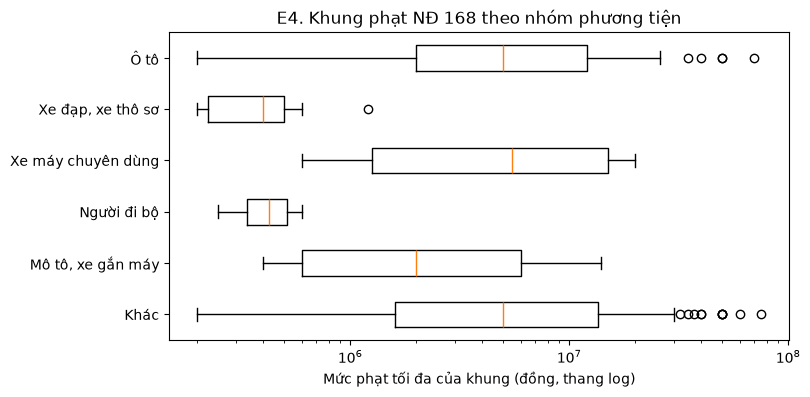

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
groups = sorted(fines["phuong_tien"].unique())
ax.boxplot([fines.loc[fines["phuong_tien"] == g, "max"] for g in groups], tick_labels=groups, vert=False)
ax.set_xscale("log")
ax.set_xlabel("Mức phạt tối đa của khung (đồng, thang log)")
ax.set_title("E4. Khung phạt NĐ 168 theo nhóm phương tiện")
save(fig, "e4_muc_phat.png")

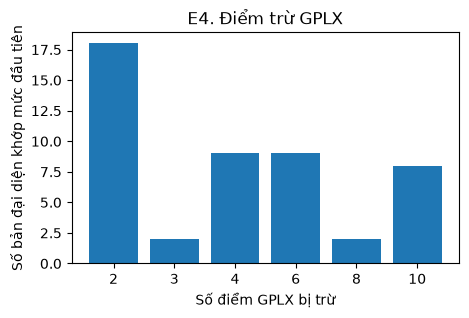

{2: 18, 3: 2, 4: 9, 6: 9, 8: 2, 10: 8}

In [13]:
pts = Counter(p for p in (eda.extract_points(t) for t in n168["text"]) if p)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar([str(k) for k in sorted(pts)], [pts[k] for k in sorted(pts)])
ax.set_xlabel("Số điểm GPLX bị trừ")
ax.set_ylabel("Số bản đại diện khớp mức đầu tiên")
ax.set_title("E4. Điểm trừ GPLX")
save(fig, "e4_tru_diem.png")
dict(sorted(pts.items()))

**Phát hiện → hành động (E4):**

- **Phát hiện:** regex tìm khung tiền đầu tiên trong 190 Khoản NĐ168, từ 100.000 đến 75.000.000 đồng; bên dưới có 574 Điểm cấu trúc → **Hành động:** ở bước trích thuộc tính, đối chiếu từng Khoản cùng Điểm, đối tượng và điều kiện; không xem 574 Điểm là số hành vi pháp lý duy nhất hoặc khung đầu tiên là toàn bộ biểu phạt.
- **Phát hiện:** phép lấy mức trừ điểm đầu tiên cho ra 48 bản đại diện: 2 điểm (18), 3 (2), 4 (9), 6 (9), 8 (2), 10 (8) → **Hành động:** trong eval mức phạt/tình huống, kiểm tra câu dẫn bổ sung và phạm vi áp dụng; bổ sung parser nhiều mức trước khi tự động lập bảng đầy đủ.

## E5. Sửa đổi, bổ sung, bãi bỏ

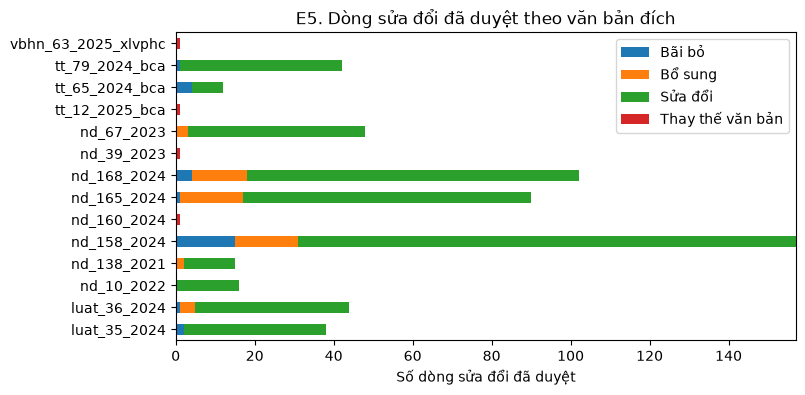

action,bai_bo,bo_sung,sua_doi,thay_the_van_ban,All
target_doc_id,,,,,
luat_35_2024,2,0,36,0,38
luat_36_2024,1,4,39,0,44
nd_10_2022,0,0,16,0,16
nd_138_2021,0,2,13,0,15
nd_158_2024,15,16,126,0,157
nd_160_2024,0,0,0,1,1
nd_165_2024,1,16,73,0,90
nd_168_2024,4,14,84,0,102
nd_39_2023,0,0,0,1,1


In [14]:
hl = {r["doc_id"]: r["hl_chot"] for r in read_csv(config.PROCESSED / "effective_dates.csv")}
ok = pd.DataFrame([r for r in read_csv(config.PROCESSED / "amendments_reviewed.csv") if r["status"] == "duyet"])
ok["ngay"] = [h or hl[a] for h, a in zip(ok["hl_rieng"], ok["amend_doc_id"])]
e5 = pd.crosstab(ok["target_doc_id"], ok["action"], margins=True)
fig, ax = plt.subplots(figsize=(8, 4))
e5.drop(index="All", columns="All").rename(columns={
    "bai_bo": "Bãi bỏ", "bo_sung": "Bổ sung", "sua_doi": "Sửa đổi",
    "thay_the_van_ban": "Thay thế văn bản",
}).plot.barh(stacked=True, ax=ax)
ax.set_xlabel("Số dòng sửa đổi đã duyệt")
ax.set_ylabel("")
ax.legend(title="")
ax.set_title("E5. Dòng sửa đổi đã duyệt theo văn bản đích")
save(fig, "e5_sua_doi.png")
e5

In [15]:
pd.crosstab(ok["amend_doc_id"], ok["ngay"])

ngay,2025-01-01,2025-03-01,2025-07-01,2026-01-01,2026-03-15,2026-05-18,2026-06-08,2026-07-01,2026-08-10,2026-08-15,2026-09-15,2027-07-01,2028-01-01,2029-01-01
amend_doc_id,,,,,,,,,,,,,,
luat_118_2025,0,0,0,1,0,0,0,81,0,0,0,0,0,0
nd_156_2024,1,0,0,0,0,0,0,0,0,0,0,0,0,0
nd_175_2025,0,0,15,0,0,0,0,0,0,0,0,0,0,0
nd_218_2026,0,0,0,0,0,0,0,0,154,0,2,0,1,0
nd_220_2026,0,0,0,0,0,0,0,48,0,0,0,0,0,0
nd_238_2026,0,0,0,0,0,0,0,0,0,99,0,0,0,3
nd_241_2026,0,0,0,0,0,0,0,90,0,0,0,0,0,0
nd_47_2026,0,0,0,0,15,0,0,0,0,0,0,0,0,0
nd_51_2025,0,1,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
amended = df[df["source_doc_id"] != df["doc_id"]]
print(f"{len(amended)} bản ghi sinh từ sửa đổi; {int((~amended['noi_dung_doi']).sum())} không đổi nội dung")
base_units = set(df.loc[df["source_doc_id"] == df["doc_id"], "unit_id"])
rq3 = amended[amended["noi_dung_doi"] & amended["level"].isin(["khoan", "diem"]) & amended["unit_id"].isin(base_units)]
print(f"Khoản/điểm có cả bản gốc và bản sửa khác nội dung (nguồn câu hỏi RQ3): {rq3['unit_id'].nunique()}")
rq3.groupby("doc_id")["unit_id"].nunique()

1128 bản ghi sinh từ sửa đổi; 208 không đổi nội dung
Khoản/điểm có cả bản gốc và bản sửa khác nội dung (nguồn câu hỏi RQ3): 731


doc_id
luat_35_2024       46
luat_36_2024       41
nd_10_2022         27
nd_138_2021        13
nd_158_2024       227
nd_165_2024       138
nd_168_2024       119
nd_67_2023         54
tt_65_2024_bca     20
tt_79_2024_bca     46
Name: unit_id, dtype: int64

**Phát hiện → hành động (E5):**

- **Phát hiện:** 568 dòng sửa đổi được duyệt gồm 481 sửa đổi, 55 bổ sung, 28 bãi bỏ và 4 thay thế văn bản → **Hành động:** ở bước truy hồi theo thời gian, sử dụng trạng thái đã duyệt và ngày hiệu lực của từng dòng, không áp dụng mọi dòng ứng viên.
- **Phát hiện:** có 1.128 phiên bản sinh từ sửa đổi và 731 địa chỉ Khoản/Điểm có cả bản gốc lẫn bản sửa khác nội dung → **Hành động:** ở bước thiết kế eval RQ3, chọn cặp trước/sau từ 731 địa chỉ này, kiểm tra điều kiện hiệu lực rồi duyệt câu hỏi thủ công; hiện chưa sinh câu hỏi.

## E6. Dòng thời gian hiệu lực 2024–2029

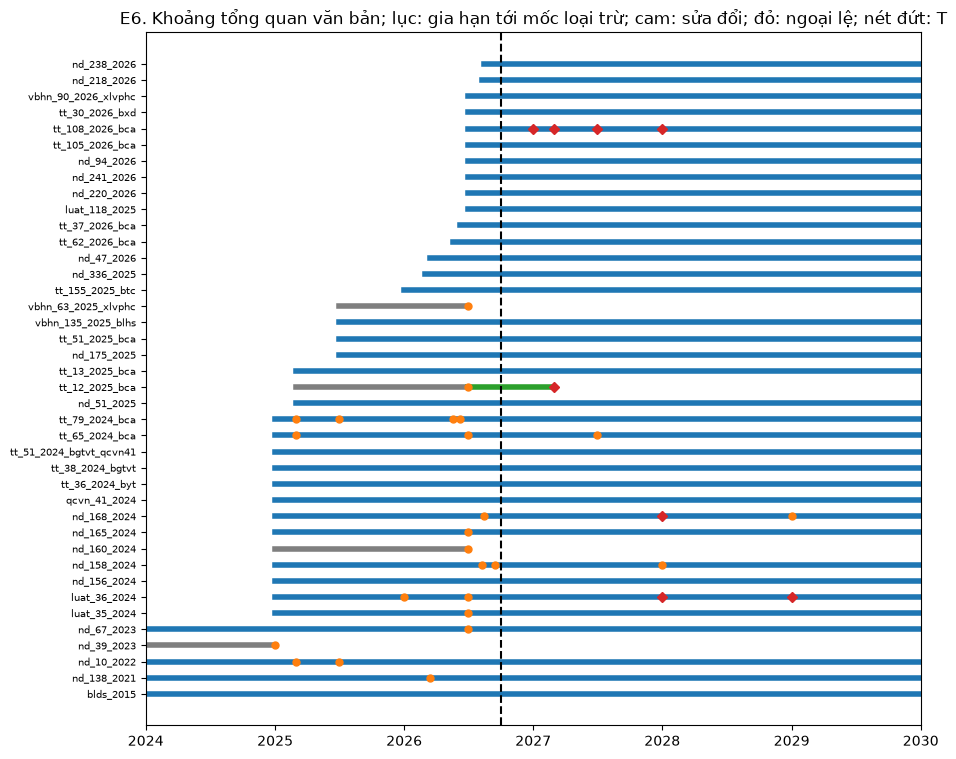

In [17]:
docs = sorted(df["doc_id"].unique(), key=lambda d: hl[d])
end = {d: (None if df.loc[df["doc_id"] == d, "valid_to"].isna().any() else df.loc[df["doc_id"] == d, "valid_to"].max())
       for d in docs}
extensions = {d: max((ex["den_ngay"] for r in recs if r["doc_id"] == d
                      for ex in r["hl_ngoai_le"] if ex["vai_tro"] == "gia_han" and ex["den_ngay"]), default=None)
              for d in docs}
x0, x1 = pd.Timestamp("2024-01-01"), pd.Timestamp("2030-01-01")
fig, ax = plt.subplots(figsize=(10, 9))
for y, d in enumerate(docs):
    s = max(pd.Timestamp(hl[d]), x0)
    e = pd.Timestamp(end[d]) if end[d] else x1
    ax.plot([s, e], [y, y], lw=4, color="tab:blue" if end[d] is None else "tab:gray")
    if extensions[d] and end[d]:
        ax.plot([e, pd.Timestamp(extensions[d])], [y, y], lw=4, color="tab:green")
    for day in sorted(set(ok.loc[ok["target_doc_id"] == d, "ngay"])):
        ax.plot(pd.Timestamp(day), y, "o", color="tab:orange", ms=5)
    for day in sorted({ex["tu_ngay"] or ex["den_ngay"] for r in recs if r["doc_id"] == d
                       for ex in r["hl_ngoai_le"]}):
        ax.plot(pd.Timestamp(day), y, "D", color="tab:red", ms=5)
ax.axvline(pd.Timestamp(T), color="black", ls="--")
ax.set_yticks(range(len(docs)), docs, fontsize=7)
ax.set_xlim(x0, x1)
ax.set_title("E6. Khoảng tổng quan văn bản; lục: gia hạn tới mốc loại trừ; cam: sửa đổi; đỏ: ngoại lệ; nét đứt: T")
save(fig, "e6_dong_thoi_gian.png")

In [18]:
fut = []
for r in recs:
    if r["valid_from"] > T:
        fut.append((r["valid_from"], r["doc_id"], "bắt đầu hiệu lực"))
    for ex in r["hl_ngoai_le"]:
        day = ex["tu_ngay"] or ex["den_ngay"]
        if day > T:
            fut.append((day, r["doc_id"], ex["loai"]))
display(pd.DataFrame(fut, columns=["ngay", "doc_id", "su_kien"]).value_counts().sort_index())
print("Gia hạn có ngày kết thúc loại trừ:", {d: x for d, x in extensions.items() if x})
print("Đồ thị tổng quan theo văn bản, không chứng minh mọi điều/khoản cùng trạng thái ở mọi ngày.")

ngay        doc_id           su_kien           
2027-01-01  tt_108_2026_bca  moc_trong_noi_dung     5
2027-03-01  tt_108_2026_bca  hoan_ap_dung           3
            tt_12_2025_bca   gia_han               17
2027-07-01  tt_108_2026_bca  moc_trong_noi_dung     1
            tt_65_2024_bca   bắt đầu hiệu lực       5
2028-01-01  luat_36_2024     hoan_ap_dung           2
            nd_158_2024      bắt đầu hiệu lực       1
            nd_168_2024      hoan_ap_dung           5
            tt_108_2026_bca  moc_trong_noi_dung     4
2029-01-01  luat_36_2024     moc_trong_noi_dung     2
            nd_168_2024      bắt đầu hiệu lực       3
Name: count, dtype: int64

Gia hạn có ngày kết thúc loại trừ: {'tt_12_2025_bca': '2027-03-01'}
Đồ thị tổng quan theo văn bản, không chứng minh mọi điều/khoản cùng trạng thái ở mọi ngày.


**Phát hiện → hành động (E6):**

- **Phát hiện:** TT12 có ngoại lệ gia hạn tới mốc kết thúc loại trừ 01/03/2027 (còn áp dụng tới hết 28/02/2027 cho đơn vị đủ điều kiện) → **Hành động:** ở bước lọc hiệu lực, gọi `in_force_at` trên từng phiên bản; không suy trạng thái từng quy định từ đoạn tổng quan theo văn bản.
- **Phát hiện:** có 48 lượt sự kiện tương lai theo bản ghi: 5 tại 01/01/2027, 20 tại 01/03/2027, 6 tại 01/07/2027, 12 tại 01/01/2028 và 5 tại 01/01/2029 → **Hành động:** ở bước kiểm thử thời gian, kiểm tra ngày ngay trước và đúng các mốc này; khử trùng khi lập lịch sự kiện thực vì số lượt không phải số sự kiện pháp lý độc lập.

## E7. Từ vựng (tách từ bằng pyvi)

C:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyvi\ViTokenizer.py:24: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  model = pickle.load(fin)


,Biển báo,Bảo hiểm,GPLX,Hướng dẫn,Luật lõi,Lệ phí,"Nộp phạt, giữ xe",Tai nạn,Tốc độ,Xử phạt,Đăng kiểm,Đăng ký xe
0,w,khớp,thí sinh,campuchia,hạng,trước bạ,giáo dưỡng,phạt,tốc độ,phạt,gcn,đấu giá
1,ie,gẫy,xi nhan,liên vận,đối tác,lệ phí,tang vật,thiệt hại,biển báo,thực hiện hành vi,kdvt,mật khẩu
2,kilômét,ngón,bài,lào,trúng,đất,bảo lãnh,tù,đường cao tốc,miligam,khí thải,trúng
3,r,tổn thương,báo danh,trung quốc,đường dây,block,niêm phong,phạm tội,km,cảnh cáo,đăng kiểm,ri
4,minh họa,phẫu thuật,xuất phát,giao đấu,d2,đăng ký,phạt,tổng tỷ lệ,thông tư,làm công,kiểm định,sê
5,e,sẹo,lý thuyết,tad,học sinh,súng,thi hành quyết định,tổn thương,trị số,cơ động,thông số,seri
6,vạch,can,hạng,gms,kết cấu hạ tầng,btc,hoãn,thương tích,trộn,biên nhận,thông tư,nhật ký
7,p,sọ,ngày sinh,thẩm tra,hàng hoá,nợ,cha mẹ,pháp nhân,téc,mililít,kiểm nghiệm,rơmoóc
8,l1,thần kinh,d2,phù hiệu,đường cao tốc,chuyển nhượng,tình tiết,bù đắp,khoảng cách,học sinh,sai số,chà số
9,mũi tên,xương,d1,hiện hữu,thông minh,tổng thành,giáo dục,giam giữ,vữa,phù hiệu,phân phối,phiên đấu giá


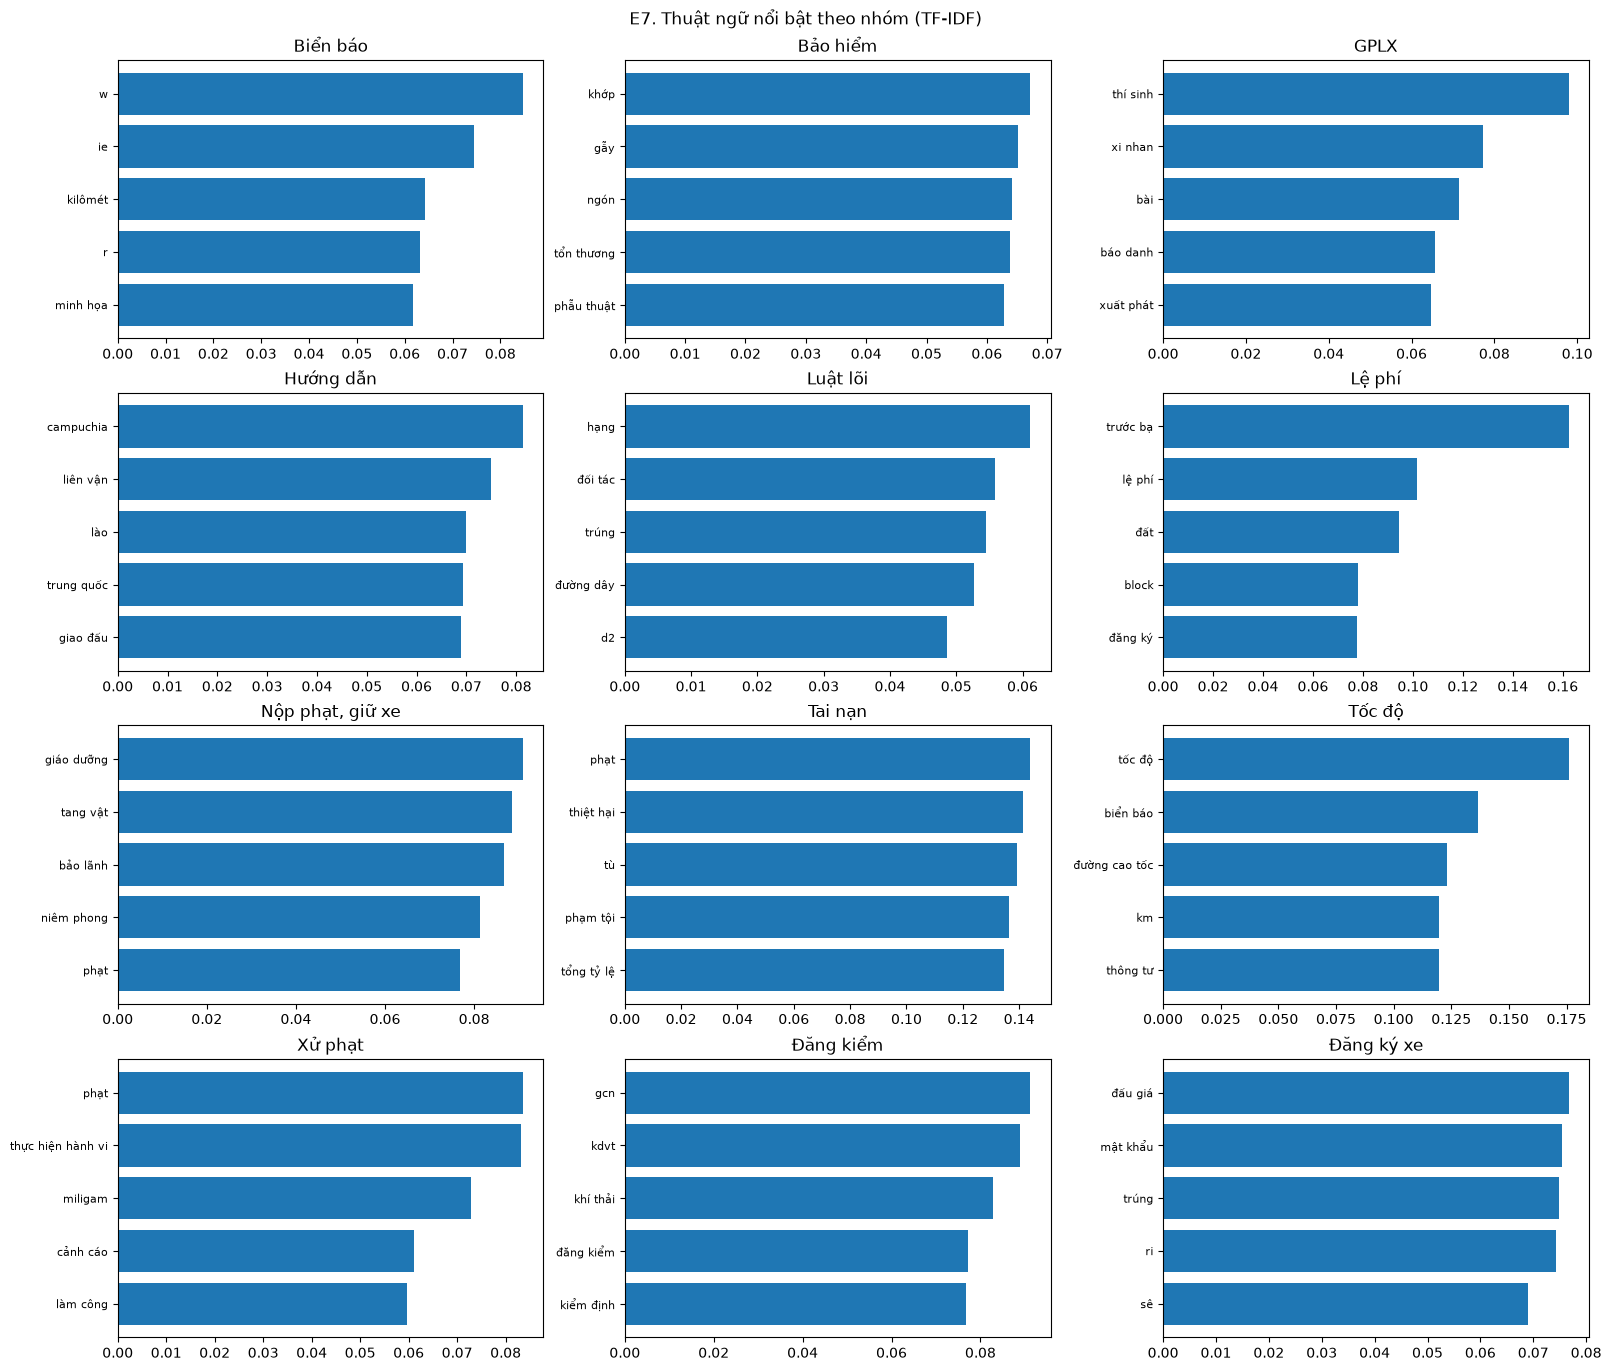

In [19]:
from pyvi import ViTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

STOP = ["của", "và", "các", "về", "đối_với", "với", "trong", "theo", "quy_định", "việc", "được", "này", "có", "là",
        "cho", "tại", "khi", "hoặc", "không", "phải", "từ", "đến", "những", "một", "do", "trường_hợp", "điều",
        "khoản", "điểm", "sau", "đây", "như", "thì", "trên", "người", "bằng"]
body = live[live["trong_pham_vi"] & (live["loai_phu_luc"] != "mau_bieu") & ~live["van_ban_sua_doi"]]
seg = {g: ViTokenizer.tokenize(" ".join(t)).lower() for g, t in body.groupby("nhom")["text"]}
vec = TfidfVectorizer(token_pattern=r"(?u)\b\w*[^\W\d_]\w*\b", stop_words=STOP, sublinear_tf=True)
X = vec.fit_transform(list(seg.values()))
terms = vec.get_feature_names_out()
top = {g: [terms[j].replace("_", " ") for j in X[i].toarray()[0].argsort()[::-1][:15]] for i, g in enumerate(seg)}
display(pd.DataFrame(top))

# Hình thứ 10: năm thuật ngữ TF-IDF nổi bật nhất mỗi nhóm (mỗi nhóm là một tài liệu phân tích).
fig, axes = plt.subplots(math.ceil(len(seg) / 3), 3,
                         figsize=(16, 3.4 * math.ceil(len(seg) / 3)), layout="constrained")
for i, (g, words) in enumerate(top.items()):
    ax = axes.flat[i]
    ax.barh(words[:5][::-1], [X[i, list(terms).index(w.replace(" ", "_"))] for w in words[:5][::-1]])
    ax.set_title(g)
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(seg):]:
    ax.axis("off")
fig.suptitle("E7. Thuật ngữ nổi bật theo nhóm (TF-IDF)")
save(fig, "e7_tu_vung.png")

In [20]:
PAIRS = [("xe mô tô", r"xe máy(?! chuyên dùng)"), ("giấy phép lái xe", r"bằng lái"), ("nồng độ cồn", r"rượu bia|rượu, bia"),
         ("xe ô tô", r"xe hơi"), ("cảnh sát giao thông", r"\bcsgt\b"), ("đèn tín hiệu", r"đèn đỏ|đèn xanh"),
         ("tạm giữ phương tiện", r"giam xe|giữ xe"), ("mũ bảo hiểm", r"nón bảo hiểm")]
corpus = "\n".join(body["text"]).lower()
pair_counts = pd.DataFrame([{"phap_ly": a, "so_lan": corpus.count(a), "doi_thuong": b,
                             "so_lan_doi_thuong": len(re.findall(b, corpus))} for a, b in PAIRS])
pair_counts

,phap_ly,so_lan,doi_thuong,so_lan_doi_thuong
0,xe mô tô,275,xe máy(?! chuyên dùng),121
1,giấy phép lái xe,885,bằng lái,1
2,nồng độ cồn,29,"rượu bia|rượu, bia",9
3,xe ô tô,863,xe hơi,0
4,cảnh sát giao thông,400,\bcsgt\b,3
5,đèn tín hiệu,130,đèn đỏ|đèn xanh,44
6,tạm giữ phương tiện,15,giam xe|giữ xe,3
7,mũ bảo hiểm,28,nón bảo hiểm,0


**Phát hiện → hành động (E7):**

- **Phát hiện:** trong tập text đã lọc, “giấy phép lái xe” xuất hiện 885 lần nhưng “bằng lái” 1 lần; “xe ô tô” 863 lần nhưng “xe hơi” 0 lần; “mũ bảo hiểm” 28 lần nhưng “nón bảo hiểm” 0 lần → **Hành động:** ở bước xử lý truy vấn, thêm ánh xạ từ đời thường sang thuật ngữ và kiểm thử câu diễn đạt khác nhau; không dùng đồng nghĩa để suy cùng phạm vi pháp lý.
- **Phát hiện:** “xe mô tô” có 275 lần, mẫu “xe máy” có 121; “đèn tín hiệu” có 130, mẫu “đèn đỏ/đèn xanh” có 44 → **Hành động:** ở bước eval truy hồi, lấy biến thể ngôn ngữ làm nhóm kiểm tra riêng và đối chiếu loại phương tiện/tình huống trước khi mở rộng truy vấn.
- **Phát hiện:** TF-IDF được tính trên 12 tài liệu gộp theo nhóm; top 5 của Biển báo có “w”, “ie”, còn Bảo hiểm có “khớp”, “gẫy” → **Hành động:** ở bước kiểm tra kho, rà mã biển, nhiễu OCR và nội dung bảng chuyên ngành; không diễn giải thứ hạng này là nhu cầu người dùng hay tần suất trên từng văn bản.

## E8. Đơn vị gần trùng giữa các văn bản

In [21]:
cand = live[(live["so_tu"] >= 30) & (live["loai_phu_luc"] != "mau_bieu") & live["trong_pham_vi"]
            & ~live["van_ban_sua_doi"]].reset_index(drop=True)
pairs = eda.near_duplicates(cand["text"].tolist(), cand["doc_id"].tolist(), threshold=0.9)
print(f"{len(cand)} đơn vị xét; {len(pairs)} cặp gần trùng (cosine TF-IDF ký tự ≥ 0,9) khác văn bản")
if pairs:
    e8 = pd.DataFrame([{"a": cand["unit_id"][i], "b": cand["unit_id"][j], "cos": s} for i, j, s in pairs])
    e8["cap"] = e8["a"].str.split(":").str[0] + " ~ " + e8["b"].str.split(":").str[0]
    display(e8["cap"].value_counts())
    display(e8.head(20))

5166 đơn vị xét; 92 cặp gần trùng (cosine TF-IDF ký tự ≥ 0,9) khác văn bản


cap
nd_168_2024 ~ nd_336_2025            48
luat_36_2024 ~ qcvn_41_2024           8
luat_36_2024 ~ nd_168_2024            5
luat_36_2024 ~ tt_79_2024_bca         4
tt_108_2026_bca ~ tt_12_2025_bca      4
luat_35_2024 ~ nd_165_2024            2
luat_35_2024 ~ luat_36_2024           2
luat_35_2024 ~ qcvn_41_2024           1
luat_35_2024 ~ tt_38_2024_bgtvt       1
luat_35_2024 ~ nd_336_2025            1
luat_36_2024 ~ nd_158_2024            1
luat_36_2024 ~ tt_108_2026_bca        1
nd_138_2021 ~ nd_158_2024             1
nd_138_2021 ~ nd_165_2024             1
nd_138_2021 ~ nd_168_2024             1
nd_138_2021 ~ nd_336_2025             1
nd_138_2021 ~ nd_67_2023              1
nd_158_2024 ~ nd_336_2025             1
nd_158_2024 ~ nd_67_2023              1
nd_165_2024 ~ nd_336_2025             1
nd_165_2024 ~ nd_67_2023              1
nd_168_2024 ~ nd_94_2026              1
nd_336_2025 ~ vbhn_90_2026_xlvphc     1
nd_336_2025 ~ nd_94_2026              1
tt_108_2026_bca ~ tt_65_2024_bca    

,a,b,cos,cap
0,luat_35_2024:d24:k7,qcvn_41_2024:d3:k15,1.0000,luat_35_2024 ~ qcvn_41_2024
1,luat_35_2024:d26:k1,tt_38_2024_bgtvt:d5:k1,0.9047,luat_35_2024 ~ tt_38_2024_bgtvt
2,luat_35_2024:d30:k3:a,nd_165_2024:d27:k2,0.9239,luat_35_2024 ~ nd_165_2024
3,luat_35_2024:d52:k2:c,nd_165_2024:d52:k1,0.9275,luat_35_2024 ~ nd_165_2024
4,luat_35_2024:d6:k3,luat_36_2024:d7:k3,0.9246,luat_35_2024 ~ luat_36_2024
5,luat_35_2024:d75:k2,nd_336_2025:d12:k2:e,0.9399,luat_35_2024 ~ nd_336_2025
6,luat_35_2024:d85:k3,luat_36_2024:d88:k3,0.9616,luat_35_2024 ~ luat_36_2024
7,luat_36_2024:d15:k4,nd_168_2024:d6:k4:i,0.9050,luat_36_2024 ~ nd_168_2024
8,luat_36_2024:d27:k2,qcvn_41_2024:d7:k1,1.0000,luat_36_2024 ~ qcvn_41_2024
9,luat_36_2024:d27:k2:a,qcvn_41_2024:d7:k1:a,1.0000,luat_36_2024 ~ qcvn_41_2024


**Phát hiện → hành động (E8):**

- **Phát hiện:** 5.166 đơn vị đủ điều kiện có 92 cặp khác văn bản đạt cosine TF-IDF ký tự ≥ 0,9 → **Hành động:** ở bước lập chỉ mục, gắn nhóm gần trùng để tránh kết quả lặp nhưng giữ mọi nguồn, ngày hiệu lực và điều kiện; không tự xóa theo độ giống chữ.
- **Phát hiện:** cặp NĐ168–NĐ336 chiếm 48/92 cặp; bảng ví dụ có Luật36 Điều 27 Khoản 2 và QCVN Điều 7 Khoản 1 đạt cosine 1,0 → **Hành động:** ở bước xếp hạng truy hồi, duyệt những cặp này để chọn nguồn thích hợp với câu hỏi; similarity không xác nhận hai quy định tương đương pháp lý.

## E9. Tham chiếu chéo

1557 tham chiếu đánh số khớp regex; 1060 / 16271 đơn vị (6.5%) có ít nhất một tham chiếu

loai
noi_bo    1389
ngoai      168
Name: count, dtype: int64

,unit_id,diem,khoan,dieu,loai,trich_ngu_canh
0,blds_2015:d102:k1,None,NaN,212,noi_bo,ghĩa vụ đối với tài sản này được xác định theo quy định tại Điều 212 của Bộ luật này.
1,blds_2015:d102:k2,None,NaN,506,noi_bo,ghĩa vụ đối với tài sản này được xác định theo quy định tại Điều 506 của Bộ luật này.
2,blds_2015:d103:k2,None,NaN,288,noi_bo,yêu cầu các thành viên thực hiện nghĩa vụ theo quy định tại Điều 288 của Bộ luật này.
3,luat_35_2024:d84:k4,None,5,51,ngoai,"Sửa đổi, bổ sung khoản 5 và bổ sung khoản 5a vào sau khoản 5 Điều 51 của Luật Điện lực số 28/2004/QH11 đã được sửa đổi, bổ sung một số điều theo Luật số 24/2012/QH13, Luật số 28/2018/QH14, Luật số 03/2022/QH15 và Luật số 16/2023/QH15 như"
4,nd_10_2022:d10:k5,None,NaN,47,ngoai,Cá nhân sử dụng đất nông nghiệp theo quy định tại Điều 47 Luật Đất đai.
5,nd_10_2022:d13:k1:b,None,NaN,1,ngoai,"m c khoản 5 Điều 8 Nghị định này (được sửa đổi, bổ sung tại Điều 1 Nghị định số 51/2025/NĐ-CP ngày 01 tháng 3 năm 2025 của Chính phủ)."


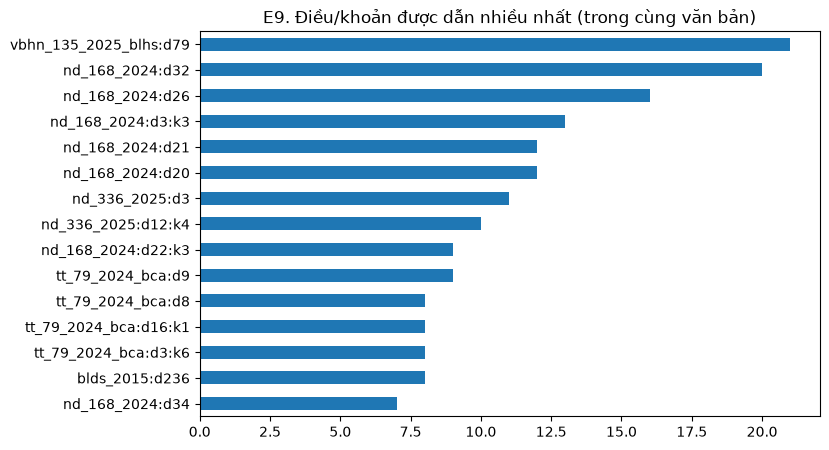

In [22]:
body9 = live[live["level"].isin(["dieu", "khoan", "diem"]) & ~live["van_ban_sua_doi"]]
refs = pd.DataFrame([{"unit_id": u, "doc_id": d, **ref} for u, d, t in zip(body9["unit_id"], body9["doc_id"], body9["text"])
                     for ref in eda.find_references(t)])
print(f"{len(refs)} tham chiếu đánh số khớp regex; {refs['unit_id'].nunique()} / {len(body9)} đơn vị "
      f"({refs['unit_id'].nunique() / len(body9):.1%}) có ít nhất một tham chiếu")
display(refs["loai"].value_counts())
# Ví dụ chỉ để rà mẫu parser; chưa phân giải địa chỉ đích hay khẳng định liên kết đầy đủ.
reference_examples = []
for kind in ("noi_bo", "ngoai"):
    for row in refs[refs["loai"] == kind].head(3).to_dict(orient="records"):
        text = body9.loc[body9["unit_id"] == row["unit_id"], "text"].iloc[0]
        matches = [(match, parsed) for match, parsed in zip(eda.REF.finditer(text), eda.find_references(text))
                   if parsed["loai"] == kind]
        match, parsed = matches[0]
        reference_examples.append({"unit_id": row["unit_id"], **parsed,
                                   "trich_ngu_canh": text[max(0, match.start() - 60):match.end() + 160]})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(reference_examples))
inner = refs[refs["loai"] == "noi_bo"]
target = inner["doc_id"] + ":d" + inner["dieu"] + inner["khoan"].fillna("").map(lambda k: f":k{k}" if k else "")
fig, ax = plt.subplots(figsize=(8, 5))
target.value_counts().head(15).sort_values().plot.barh(ax=ax)
ax.set_title("E9. Điều/khoản được dẫn nhiều nhất (trong cùng văn bản)")
save(fig, "e9_tham_chieu.png")

**Phát hiện → hành động (E9):**

- **Phát hiện:** regex khớp 1.557 tham chiếu đánh số trong 1.060/16.271 đơn vị (6,5%), gồm 1.389 nội bộ và 168 bên ngoài → **Hành động:** ở bước truy hồi, thử mở rộng ngữ cảnh theo Điều/Khoản đích và kiểm tra đúng văn bản/phiên bản trước khi đưa vào câu trả lời.
- **Phát hiện:** 168 kết quả được parser gắn nhãn bên ngoài; phép đếm chỉ bao phủ các mẫu đánh số đã hỗ trợ → **Hành động:** ở bước xây đồ thị tham chiếu, duyệt ví dụ bên ngoài và mở rộng nhận diện tên văn bản; không xem đơn vị không khớp regex là không có tham chiếu hoặc kết quả regex là liên kết đã giải quyết.

## E10. Chất lượng sau làm sạch

Đơn vị rỗng (không tiêu đề, không nội dung)      0
Đơn vị có dòng phần kết                          0
unit_id có hậu tố #                              0
Bản ghi chat_luong = kem                        17
Ký tự lạ (tổng số lần)                         634
dtype: int64

,count,mean,std,min,50%,90%,99%,max
method,,,,,,,,
docx,14839.0,0.0031,0.0234,0.0,0.0,0.0,0.1000,0.5385
pdf,2780.0,0.0002,0.0018,0.0,0.0,0.0,0.0036,0.0448
txt,52.0,0.0007,0.0031,0.0,0.0,0.0,0.0144,0.0175


Ký tự lạ hay gặp: [('♦', 280), ('□', 160), ('\uf06f', 77), ('\uf0a3', 31), ('☐', 23), ('≤', 13), ('≥', 12), ('√', 9), ('\uf0a8', 8), ('●', 6), ('‰', 6), ('±', 3), ('\uf0a0', 3), ('\uf02a', 2), ('‟', 1)]
Nhãn chất lượng là heuristic tỷ lệ âm tiết lạ, không phải độ chính xác OCR. Ký hiệu Unicode lạ cần kiểm tra ngữ cảnh trước khi sửa.
Kiểm tra danh sách khoảng trống đã được đối chiếu nguồn tại PROCESSING_REPORT.md: 4 phụ lục QCVN không có đơn vị: ['Phụ lục M', 'Phụ lục N', 'Phụ lục O', 'Phụ lục P']


,unit_id,title,text,chat_luong,thieu_noi_dung,text_characters
9648,nd_39_2023:pl1,Phụ lục,(Kèm theo Nghị định số 39/2023/NĐ-CP ngày 26 tháng 6 năm 2023\ncủa Chính Phủ),ok,"Phụ lục là ảnh trong bản Công báo, chưa có chữ; dữ liệu chỉ còn dòng ""Kèm theo Nghị định""",76


Độ ngắn/không có đơn vị là bằng chứng văn bản hiện lưu; kết luận thiếu nội dung dựa vào đối chiếu nguồn ở báo cáo làm sạch, không chỉ từ ngưỡng độ dài. Danh sách không phải kiểm kê đầy đủ.


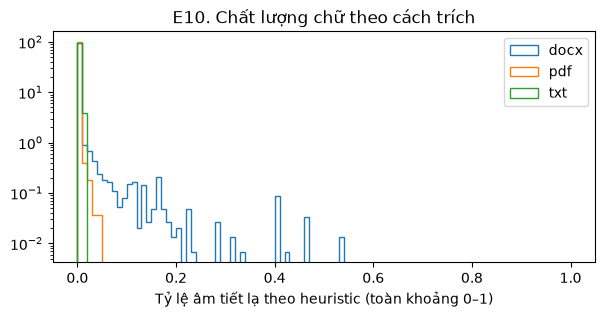

In [23]:
PUNCT = set(".,;:!?()[]{}\"'“”‘’/\\%&+-–—…|*#°§<>=_~^@$€₫·•")
odd = Counter(c for t in live["text"] for c in t if not (c.isalnum() or c.isspace() or c in PUNCT))
live["method"] = live["doc_id"].map(method)
e10 = {
    "Đơn vị rỗng (không tiêu đề, không nội dung)": int(((live["text"].str.strip() == "")
                                                       & (live["title"].str.strip() == "")).sum()),
    "Đơn vị có dòng phần kết": int(sum(any(is_closing_line(x) for x in t.splitlines())
                                        for t, lvl in zip(live["text"], live["level"]) if lvl in ("dieu", "khoan", "diem"))),
    "unit_id có hậu tố #": int(live["unit_id"].str.contains("#").sum()),
    "Bản ghi chat_luong = kem": int((live["chat_luong"] == "kem").sum()),
    "Ký tự lạ (tổng số lần)": sum(odd.values()),
}
display(pd.Series(e10))
display(live.groupby("method")["ty_le_am_tiet_loi"].describe(percentiles=[0.5, 0.9, 0.99]).round(4))
print("Ký tự lạ hay gặp:", odd.most_common(20))
print("Nhãn chất lượng là heuristic tỷ lệ âm tiết lạ, không phải độ chính xác OCR. "
      "Ký hiệu Unicode lạ cần kiểm tra ngữ cảnh trước khi sửa.")
annex_all = df[df["level"] == "phu_luc"].drop_duplicates("unit_id", keep="last")
qcvn_annex_titles = annex_all.loc[annex_all["doc_id"] == "qcvn_41_2024", "title"].tolist()
known_qcvn_gap_letters = ["M", "N", "O", "P"]
missing_qcvn_titles = [f"Phụ lục {letter}" for letter in known_qcvn_gap_letters
                      if f"Phụ lục {letter}" not in qcvn_annex_titles]
stub_audit = df[df["thieu_noi_dung"].notna()].drop_duplicates("unit_id", keep="last")[
    ["unit_id", "title", "text", "chat_luong", "thieu_noi_dung"]].copy()
stub_audit["text_characters"] = stub_audit["text"].str.len()
source_gap_audit = {
    "evidence_report": "data/processed/PROCESSING_REPORT.md",
    "scope": "All stored versions, independent of cutoff; QCVN M-P plus units flagged thieu_noi_dung, not an exhaustive audit",
    "qcvn_annex_titles_present": qcvn_annex_titles,
    "known_qcvn_titles_absent": missing_qcvn_titles,
    "known_stub_units": stub_audit.to_dict(orient="records"),
}
print("Kiểm tra danh sách khoảng trống đã được đối chiếu nguồn tại PROCESSING_REPORT.md:",
      len(missing_qcvn_titles), "phụ lục QCVN không có đơn vị:", missing_qcvn_titles)
with pd.option_context("display.max_colwidth", None):
    display(stub_audit)
print("Độ ngắn/không có đơn vị là bằng chứng văn bản hiện lưu; kết luận thiếu nội dung dựa vào "
      "đối chiếu nguồn ở báo cáo làm sạch, không chỉ từ ngưỡng độ dài. Danh sách không phải kiểm kê đầy đủ.")
fig, ax = plt.subplots(figsize=(7, 3))
for m, g in live.groupby("method"):
    ax.hist(g["ty_le_am_tiet_loi"], bins=100, range=(0, 1), histtype="step", label=m, density=True)
ax.set_yscale("log")
ax.set_xlabel("Tỷ lệ âm tiết lạ theo heuristic (toàn khoảng 0–1)")
ax.legend()
ax.set_title("E10. Chất lượng chữ theo cách trích")
save(fig, "e10_chat_luong.png")

**Phát hiện → hành động (E10):**

- **Phát hiện:** tập đại diện có 0 đơn vị rỗng cả tiêu đề/nội dung, 0 dòng phần kết lẫn trong Điều/Khoản/Điểm và 0 địa chỉ có hậu tố `#` → **Hành động:** giữ ba kiểm tra này làm cổng kiểm định khi nhập lại dữ liệu; các số 0 không chứng minh nguồn đã đủ.
- **Phát hiện:** có 17 bản đại diện nhãn `kem` và 634 lượt ký tự ngoài tập cho phép, trong đó “♦” 280, “□” 160, ký hiệu ô chọn riêng “” 77 → **Hành động:** ở bước rà chất lượng, kiểm tra ngữ cảnh và đối chiếu nguồn trước khi sửa; nhãn âm tiết lạ không phải phép đo độ chính xác OCR, ký hiệu toán/ô chọn có thể hợp lệ.
- **Phát hiện:** 152 phụ lục tại T gồm 105 mẫu biểu và 47 nội dung; kiểm tra toàn bộ phiên bản không tìm thấy 4 phụ lục QCVN M/N/O/P; NĐ39 `pl1` chỉ có 76 ký tự và mang cờ `thieu_noi_dung` (phụ lục là ảnh); TT108 `pl12` đã có đủ chữ (486 ký tự) → **Hành động:** tách mẫu biểu khi dựng kho RAG; bổ sung nguồn ảnh/bảng và thân phụ lục theo [báo cáo làm sạch](../data/processed/PROCESSING_REPORT.md) trước khi dùng những phần này cho eval hoặc trả lời đầy đủ.

## Ma trận đề cho bộ eval thủ công (~150 câu)

Quy tắc: số câu mỗi nhóm tỷ lệ với √(số Điều có hiệu lực trong phạm vi, không tính văn bản sửa đổi và đề thi),
nhân trọng số 1,5 cho Xử phạt, GPLX, Đăng ký xe; mỗi nhóm tối thiểu 5 câu; chia loại câu theo `eda.LOAI_SPLIT`.
Đây là đề xuất ban đầu; duyệt, điều chỉnh rồi chốt trước khi viết bộ eval.

In [24]:
core = live[live["trong_pham_vi"] & ~live["van_ban_sua_doi"] & ~live["doc_id"].isin(config.NON_LEGAL)]
cnt = core[core["level"] == "dieu"].groupby("nhom").size()
docs_by = core.groupby("nhom")["doc_id"].agg(lambda s: sorted(set(s)))
matrix = pd.DataFrame(eda.eval_matrix(cnt.to_dict(), docs_by.to_dict(), total=150, floor=5))
out = ROOT / "data" / "eval" / "eval_matrix.csv"
out.parent.mkdir(parents=True, exist_ok=True)
if not out.exists():
    matrix.to_csv(out, index=False, encoding="utf-8-sig")
    print(f"Đã tạo bản đề xuất -> {out.relative_to(ROOT)}")
else:
    saved = pd.read_csv(out, encoding="utf-8-sig").fillna("")
    if saved.to_csv(index=False) == matrix.to_csv(index=False):
        print("Ma trận đang lưu khớp bản đề xuất tính lại; giữ nguyên file.")
    else:
        print("Ma trận đang lưu khác bản đề xuất tính lại; giữ nguyên chỉnh sửa thủ công. "
              "Bảng dưới và summary.json chỉ mô tả bản đề xuất tính lại để đối chiếu.")
print(f"{int(matrix['so_cau'].sum())} suất câu hỏi đề xuất; chưa tạo câu hỏi và chưa duyệt phân bổ")
matrix.pivot_table(index="chu_de", columns="loai_cau", values="so_cau", aggfunc="sum", fill_value=0, margins=True)

Ma trận đang lưu khớp bản đề xuất tính lại; giữ nguyên file.
150 suất câu hỏi đề xuất; chưa tạo câu hỏi và chưa duyệt phân bổ


loai_cau,chung,hành vi cấm,mức phạt,thủ tục,tình huống,định nghĩa,All
chu_de,,,,,,,
Biển báo,3,0,0,0,3,6,12
Bảo hiểm,3,0,0,6,3,0,12
GPLX,4,0,0,9,4,0,17
Hướng dẫn,4,0,0,7,3,0,14
Luật lõi,4,4,0,0,4,3,15
Lệ phí,5,0,0,4,0,0,9
"Nộp phạt, giữ xe",4,0,0,7,3,0,14
Tai nạn,2,0,2,0,5,0,9
Tốc độ,4,0,0,0,4,0,8


## Số liệu kiểm chứng và nguồn gốc

`summary.json` được tạo lại từ chính phép tính trong notebook. Không chứa nhận xét viết tay.

In [25]:
summary = {
    "cutoff": T,
    "inputs": {"processed_versions": len(df), "active_versions": len(live_all),
               "active_distinct_units": len(live), "documents": int(df["doc_id"].nunique()),
               "conditional_active_versions": int(live_all["dieu_kien_hl"].notna().sum()),
               "multi_branch_unit_ids": int(variants["unit_id"].nunique())},
    "tokenizers": [{"name": x["name"], "url": x["url"], "bytes": x["bytes"], "sha256": x["sha256"]}
                   for x in tokenizer_provenance],
    "E1": {"units_by_group": {k: int(v) for k, v in e1_nhom["don_vi"].items()},
           "amending_documents": int(sd["doc_id"].nunique()), "amending_document_units": len(sd),
           "levels": {k: int(v) for k, v in live["level"].value_counts().items()}},
    "E2": {"large_doc_units": len(big), "large_doc_in_scope": int(big["trong_pham_vi"].sum()),
           "large_doc_out_scope": int((~big["trong_pham_vi"]).sum()),
           "scope": {k: list(v) for k, v in SCOPE.items()}},
    "E3": {"clause_candidates": len(kh_tok), "clause_bge_p50": float(kh_tok.quantile(.5)),
           "clause_bge_p95": float(kh_tok.quantile(.95)),
           "clause_over_512": int((kh_tok > 512).sum()),
           "core_clause_candidates": len(core_kh_tok), "core_clause_over_512": int((core_kh_tok > 512).sum()),
           "core_clause_bge_p95": float(core_kh_tok.quantile(.95)),
           "short_under_5_words": len(short),
           "clause_body_only_bge_p50": float(kh_body_tok.quantile(.5)),
           "clause_body_only_bge_p95": float(kh_body_tok.quantile(.95)),
           "clause_body_only_over_512": int((kh_body_tok > 512).sum()),
           "heading_token_delta_p50": float((kh_tok - kh_body_tok).quantile(.5)),
           "heading_token_delta_p95": float((kh_tok - kh_body_tok).quantile(.95)),
           "conditional_branch_body_tokens": variant_lengths.to_dict(orient="records")},
    "E4": {"first_fine_frames": len(fines), "structured_points_under_frames": int(fines["so_diem_cau_truc"].sum()),
           "first_fine_min": int(fines["min"].min()), "first_fine_max": int(fines["max"].max()),
           "points_first_match": {str(k): int(v) for k, v in sorted(pts.items())}},
    "E5": {"reviewed_rows": len(ok), "reviewed_actions": {k: int(v) for k, v in ok["action"].value_counts().items()},
           "amended_versions": len(amended), "content_changed_clause_point_unit_ids": int(rq3["unit_id"].nunique())},
    "E6": {"exception_extensions_exclusive_end": {k: v for k, v in extensions.items() if v},
           "future_events": len(fut), "future_events_by_date": {k: int(v) for k, v in
            pd.DataFrame(fut, columns=["ngay", "doc_id", "su_kien"])["ngay"].value_counts().sort_index().items()}},
    "E7": {"groups": len(seg), "top_terms": {k: v[:5] for k, v in top.items()},
           "legal_colloquial_counts": pair_counts.to_dict(orient="records")},
    "E8": {"candidates": len(cand), "near_duplicate_pairs": len(pairs)},
    "E9": {"units_checked": len(body9), "matched_references": len(refs),
           "units_with_reference": int(refs["unit_id"].nunique()),
           "reference_types": {k: int(v) for k, v in refs["loai"].value_counts().items()}},
    "E10": {"quality_checks": e10, "odd_top20": [[k, v] for k, v in odd.most_common(20)],
            "active_annex_types": {k: int(v) for k, v in live["loai_phu_luc"].value_counts().items()},
            "source_gap_audit": source_gap_audit},
    "eval_proposal": {"rows": len(matrix), "total_slots": int(matrix["so_cau"].sum()),
                      "slots_by_group": {k: int(v) for k, v in matrix.groupby("chu_de")["so_cau"].sum().items()},
                      "slots_by_type": {k: int(v) for k, v in matrix.groupby("loai_cau")["so_cau"].sum().items()}},
}
summary_path = ROOT / "reports/eda/summary.json"
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print(f"-> {summary_path.relative_to(ROOT)}")

-> reports\eda\summary.json
